# Módulo 6 (Capstone) — Inteligencia NLP + RAG sobre Reportes de Incidentes HSE
**Pungo Academy · Reto Integrador Independiente (Nivel Avanzado)**

## Escenario del Reto
La gerencia de Seguridad de Procesos (HSE) cuenta con **500 reportes históricos de incidentes (`curso_nlp_incident_reports.csv`)** que presentan:
1. **20 registros críticos sin etiqueta de severidad (`NaN`)** que bloquean los tableros regulatorios.
2. Textos narrativos no estructurados con tags de equipos, acciones de respuesta y riesgos de turno.
3. Necesidad de auditar si los incidentes críticos cumplieron los requisitos de **Permisos de Trabajo, LOTO y Monitoreo de Gas** establecidos en `10_seguridad_permisos_trabajo.md`.

## Entregables del Capstone
1. **Auditoría y EDA HSE** por turno, severidad y categoría.
2. **Clasificador Baseline vs. GPT JSON Mode** para imputar las **20 severidades faltantes**.
3. **NER Híbrido (Regex + GPT)** sobre narrativas y acciones para extraer equipos y medidas HSE.
4. **Cruce RAG de Cumplimiento Normativo** sobre los incidentes más graves frente a los SOPs de seguridad.

In [1]:
import importlib.util, subprocess, sys
for pkg in ("openai", "requests"):
    if importlib.util.find_spec(pkg) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

import json, re, time
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Paleta corporativa oficial Pungo Tech 2027
PUNGO_NAVY = "#0D202B"
PUNGO_BLUE = "#007297"
PUNGO_LIME = "#8EC14B"
PUNGO_AMBER = "#E8820C"
PUNGO_RED = "#C0392B"
PUNGO_SLATE = "#475569"
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 150
plt.rcParams["font.size"] = 11
plt.rcParams["axes.edgecolor"] = "#CBD5E1"
plt.rcParams["axes.titleweight"] = "bold"
plt.style.use("seaborn-v0_8-whitegrid")

In [2]:
# Configuración Dual-Mode: OpenAI API (primario) + Modo Local Sin API Key (fallback)
import os
import getpass
from openai import OpenAI

api_key = os.environ.get("OPENAI_API_KEY", "").strip()
if not api_key:
    try:
        api_key = getpass.getpass(
            "Ingresa tu OpenAI API Key (o presiona Enter para Modo Local sin costo): "
        ).strip()
    except Exception:
        api_key = ""

USE_OPENAI = bool(api_key)
client = OpenAI(api_key=api_key) if USE_OPENAI else None
print(
    f"Modo activo: {'OpenAI API Live (gpt-4o-mini + text-embedding-3-small)' if USE_OPENAI else 'Modo Local Determinístico (TF-IDF + Reglas)'}"
)

Modo activo: OpenAI API Live (gpt-4o-mini + text-embedding-3-small)


## Paso 1: Carga, Auditoría de Nulos y EDA de los 500 Incidentes HSE

In [3]:
df_inc = pd.read_csv("https://d29ikw7e1z6k4e.cloudfront.net/curso_nlp/curso_nlp_incident_reports.csv", parse_dates=["fecha_evento"])
print(f"Total reportes HSE     : {len(df_inc):,}")
print(f"Rango de fechas        : {df_inc['fecha_evento'].min().date()} → {df_inc['fecha_evento'].max().date()}")
print(f"Registros sin severidad: {df_inc['severidad'].isna().sum()} (objetivo de imputación)")
print("\nDistribución por categoría:")
print(df_inc["categoria"].value_counts().to_string())
print("\nDistribución por turno:")
print(df_inc["turno"].value_counts().to_string())

Total reportes HSE     : 500
Rango de fechas        : 2023-01-02 → 2024-12-29
Registros sin severidad: 20 (objetivo de imputación)

Distribución por categoría:
categoria
paro_no_programado    157
falla_equipo          105
derrame                97
casi_accidente         77
alarma_gas             35
lesion_personal        17
incendio_conato        12

Distribución por turno:
turno
día          171
noche        169
madrugada    160


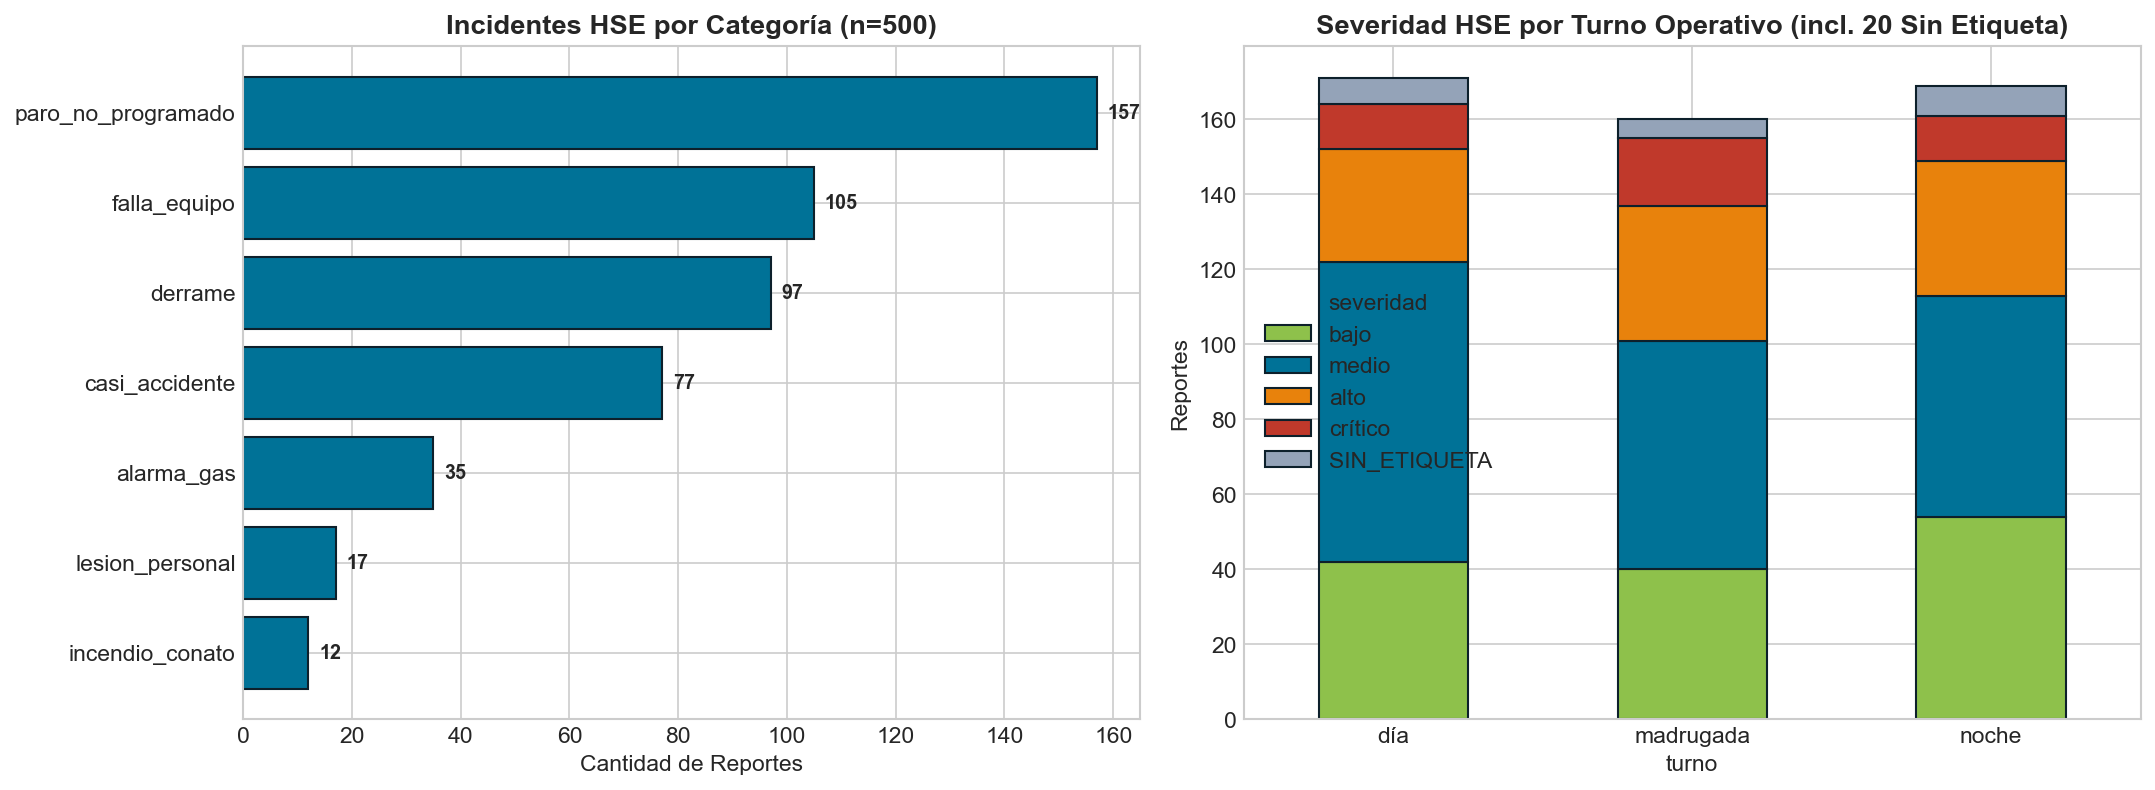

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.4))

cat_cnt = df_inc["categoria"].value_counts().sort_values(ascending=True)
axes[0].barh(cat_cnt.index, cat_cnt.values, color=PUNGO_BLUE, edgecolor=PUNGO_NAVY)
for i, v in enumerate(cat_cnt.values):
    axes[0].text(v + 2, i, str(v), va="center", fontweight="bold", fontsize=9.5)
axes[0].set_title("Incidentes HSE por Categoría (n=500)")
axes[0].set_xlabel("Cantidad de Reportes")

piv = pd.crosstab(df_inc["turno"], df_inc["severidad"].fillna("SIN_ETIQUETA"))
cols_order = [c for c in ["bajo", "medio", "alto", "crítico", "SIN_ETIQUETA"] if c in piv.columns]
piv[cols_order].plot(kind="bar", stacked=True, ax=axes[1], color=[PUNGO_LIME, PUNGO_BLUE, PUNGO_AMBER, PUNGO_RED, "#94A3B8"], edgecolor=PUNGO_NAVY)
axes[1].set_title("Severidad HSE por Turno Operativo (incl. 20 Sin Etiqueta)")
axes[1].set_ylabel("Reportes")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

## Paso 2: Baseline ML + Imputación Inteligente con GPT JSON Mode (20 Reportes sin Severidad)
Usamos los 480 incidentes etiquetados para validar predicción de `area` / `turno` / `severidad` y aplicamos **GPT JSON Mode** para auditar e imputar los 20 reportes con `severidad == NaN`.

In [5]:
df_inc["texto_hse"] = (
    "Resumen: " + df_inc["resumen"].fillna("")
    + "\nAcciones: " + df_inc["acciones_tomadas"].fillna("")
)
df_lab = df_inc[df_inc["severidad"].notna()].copy()
df_unlab = df_inc[df_inc["severidad"].isna()].copy()

X_tr, X_te, y_tr, y_te = train_test_split(df_lab["texto_hse"], df_lab["area"], test_size=0.2, random_state=42, stratify=df_lab["area"])
vec_area = TfidfVectorizer(max_features=600, ngram_range=(1, 2))
clf_area = LogisticRegression(max_iter=1000, random_state=42).fit(vec_area.fit_transform(X_tr), y_tr)
acc_area = accuracy_score(y_te, clf_area.predict(vec_area.transform(X_te)))

PROMPT_HSE_IMP = """Eres líder de Seguridad de Procesos (PSM/HSE). Evalúa el incidente e infiere:
{"severidad": "bajo"|"medio"|"alto"|"crítico", "requiere_moc": true|false, "requiere_loto": true|false, "justificacion": "1 oración"}
Responde SOLO en JSON válido."""

def imputar_hse(row) -> dict:
    txt = f"Categoría: {row['categoria']} | Equipos: {row['equipos_involucrados']}\n{row['texto_hse']}"
    if USE_OPENAI:
        try:
            resp = client.chat.completions.create(
                model="gpt-4o-mini",
                messages=[{"role": "system", "content": PROMPT_HSE_IMP}, {"role": "user", "content": txt}],
                temperature=0,
                response_format={"type": "json_object"},
            )
            return json.loads(resp.choices[0].message.content)
        except Exception as exc:
            print(f"Fallback HSE: {exc}")
    tl = txt.lower()
    sev = "crítico" if any(k in tl for k in ["emergencia", "gas", "derrame", "evacuación"]) else ("alto" if "paro" in tl else "medio")
    return {"severidad": sev, "requiere_moc": "cambio" in tl, "requiere_loto": "aislamiento" in tl or "mantenimiento" in tl, "justificacion": "Heurística local HSE."}

imputaciones = [imputar_hse(r) for _, r in df_unlab.iterrows()]
df_unlab["severidad_imputada"] = [x.get("severidad", "medio") for x in imputaciones]
df_unlab["requiere_loto"] = [bool(x.get("requiere_loto", False)) for x in imputaciones]

print(f"Accuracy TF-IDF en predicción de Área (n={len(y_te)}): {acc_area:.1%}")
print("\nDistribución imputada en los 20 incidentes sin severidad:")
print(df_unlab["severidad_imputada"].value_counts().to_string())
df_unlab[["reporte_id", "categoria", "equipos_involucrados", "severidad_imputada", "requiere_loto"]].head(6)

Accuracy TF-IDF en predicción de Área (n=96): 58.3%

Distribución imputada en los 20 incidentes sin severidad:
severidad_imputada
medio    13
bajo      6
alto      1


,reporte_id,categoria,equipos_involucrados,severidad_imputada,requiere_loto
5,RI-2024-0328,falla_equipo,P-101A,medio,False
17,RI-2024-0171,lesion_personal,C-101,medio,True
37,RI-2024-0199,paro_no_programado,"FCV-1002, V-103",medio,False
39,RI-2024-0019,paro_no_programado,"AT-1505, FT-1503",bajo,False
49,RI-2024-0493,paro_no_programado,E-201,medio,False
51,RI-2024-0394,falla_equipo,PCV-1003,medio,False


## Paso 3: Extracción NER de Equipos Críticos en Incidentes
Extraemos todos los tags de equipos involucrados en los 500 reportes HSE e identificamos los activos con mayor recurrencia en incidentes `alto` o `crítico`.

In [6]:
df_inc["tags_extraidos"] = df_inc["equipos_involucrados"].fillna("").apply(
    lambda s: re.findall(r"\b([A-Z]{1,3}-\d{2,4}[A-B]?)\b", str(s))
)
crit_tags = [
    tag
    for tags in df_inc[df_inc["severidad"].isin(["alto", "crítico"])]["tags_extraidos"]
    for tag in tags
]
top_crit = Counter(crit_tags).most_common(10)
print("TOP 10 ACTIVOS INVOLUCRADOS EN INCIDENTES ALTOS O CRÍTICOS:")
for eq, cnt in top_crit:
    print(f"  {eq:10s} → {cnt} incidentes graves")

TOP 10 ACTIVOS INVOLUCRADOS EN INCIDENTES ALTOS O CRÍTICOS:
  GAS-001    → 10 incidentes graves
  V-301      → 9 incidentes graves
  TK-201     → 8 incidentes graves
  TK-101     → 8 incidentes graves
  C-103      → 8 incidentes graves
  G-101      → 8 incidentes graves
  P-101A     → 7 incidentes graves
  C-101      → 7 incidentes graves
  V-103      → 7 incidentes graves
  P-401      → 7 incidentes graves


## Paso 4: Auditoría Cruzada RAG contra Procedimiento de Seguridad (`10_seguridad_permisos_trabajo.md`)
Cargamos el estándar oficial de permisos de trabajo, LOTO y gas H2S/LEL, y auditamos automáticamente 3 incidentes críticos para generar **recomendaciones normativas trazables**.

In [7]:
sop_seg = requests.get("https://d29ikw7e1z6k4e.cloudfront.net/curso_nlp/curso_nlp_maintenance_docs/10_seguridad_permisos_trabajo.md", timeout=20).text
sop_chunks = [ch.strip() for ch in sop_seg.split("\n## ") if ch.strip()]

if USE_OPENAI:
    resp_embs = client.embeddings.create(input=sop_chunks, model="text-embedding-3-small")
    sop_mat = np.array([d.embedding for d in resp_embs.data], dtype=np.float64)
    def embed_q(q: str) -> np.ndarray:
        return np.array(client.embeddings.create(input=q, model="text-embedding-3-small").data[0].embedding, dtype=np.float64)
else:
    vec_sop = TfidfVectorizer(ngram_range=(1, 2)).fit(sop_chunks)
    sop_mat = vec_sop.transform(sop_chunks).toarray()
    def embed_q(q: str) -> np.ndarray:
        return vec_sop.transform([q]).toarray()[0]

def auditar_incidente_rag(row) -> dict:
    q = f"{row['categoria']} {row['resumen']} {row['acciones_tomadas']}"
    qv = embed_q(q)
    sims = np.array([float(np.dot(qv, s) / (np.linalg.norm(qv) * np.linalg.norm(s) + 1e-12)) for s in sop_mat])
    best_idx = sims.argsort()[-2:][::-1]
    ctx = "\n---\n".join(sop_chunks[i] for i in best_idx)
    if USE_OPENAI:
        resp = client.chat.completions.create(
            model="gpt-4o-mini",
            messages=[
                {"role": "system", "content": "Audita el incidente HSE citando controles obligatorios (LOTO, LEL, H2S, MOC) del SOP entregado."},
                {"role": "user", "content": f"SOP:\n{ctx}\n\nIncidente {row['reporte_id']} ({row['equipos_involucrados']}):\n{row['resumen']}\nAcciones: {row['acciones_tomadas']}"},
            ],
            temperature=0.1,
            max_tokens=220,
        )
        obs = resp.choices[0].message.content
    else:
        obs = f"Sección SOP aplicable: {sop_chunks[best_idx[0]].splitlines()[0]}"
    return {"reporte_id": row["reporte_id"], "sim_sop": float(sims[best_idx[0]]), "observacion": obs}

crit_sample = df_inc[df_inc["severidad"] == "crítico"].head(3)
auditorias = [auditar_incidente_rag(r) for _, r in crit_sample.iterrows()]
for au in auditorias:
    print("=" * 72)
    print(f"{au['reporte_id']} (similitud SOP={au['sim_sop']:.3f})\n{au['observacion']}")

RI-2024-0453 (similitud SOP=0.615)
### Auditoría del Incidente HSE RI-2024-0453

**Fecha del Incidente:** 02/01/2023  
**Hora del Incidente:** 14:15 hrs  
**Ubicación:** Estación M-101A, Tanque TK-102  

#### Resumen del Incidente
El operador de turno reportó una alarma de alta concentración de H2S, lo que activó el plan de respuesta de emergencia. Se notificó a los supervisores y se realizó una investigación preliminar.

#### Controles Obligatorios Citados en el SOP

1. **Mediciones de Gas (LEL y H2S):**
   - **Requerimiento:** Se deben realizar mediciones de gas (LEL, O2, H2S) antes de iniciar cualquier trabajo en el área.
   - **Incumplimiento Potencial:** No se menciona si se realizaron mediciones de gas antes del incidente, lo cual es crítico para la seguridad.

2. **Acciones Inmediatas ante Alarma de H2S:**
  
RI-2024-0357 (similitud SOP=0.512)
### Auditoría del Incidente HSE RI-2024-0357

**Fecha del Incidente:** 02/01/2023  
**Ubicación:** Planta de tratamiento  
**Descripción 

In [8]:
# Resumen reproducible final del Capstone HSE
resumen_capstone = {
    "total_incidentes": int(len(df_inc)),
    "nulos_imputados": int(len(df_unlab)),
    "accuracy_area_tfidf": round(float(acc_area), 4),
    "top_activo_critico": top_crit[0][0] if top_crit else "N/A",
    "auditorias_rag_completadas": len(auditorias),
}
print("\nRESUMEN REPRODUCIBLE CAPSTONE HSE:")
print(json.dumps(resumen_capstone, ensure_ascii=False, indent=2))


RESUMEN REPRODUCIBLE CAPSTONE HSE:
{
  "total_incidentes": 500,
  "nulos_imputados": 20,
  "accuracy_area_tfidf": 0.5833,
  "top_activo_critico": "GAS-001",
  "auditorias_rag_completadas": 3
}
